In [27]:
from __future__ import annotations

import os
import re 
import glob
import hashlib
from dataclasses import dataclass
from typing import Dict, List, Optional, Sequence, Tuple, Union

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [28]:
@dataclass
class DiagConfig:
    base_file: str
    member_files: List[str]
    out_dir: str = "./ens_ic_diag_out"

    lev_dim_candidates: Tuple[str, ...] = ("lev", "ilev", "plev")

    sample_per_member: int = 250_000
    seed: int = 7

    variables: Tuple[str, ...] = ("T",)

@dataclass
class BfbReport:
    same_hash: bool
    base_hash: str
    other_hash: str
    maxabs_by_var: Dict[str, float]

@dataclass
class PerturbationStats:
    per_member: Dict[str, Dict[str, Dict[str, float]]]
    pooled: Dict[str, Dict[str, float]]
    
class EnsembleICDiagnostics:
    """
    Diagnostics for EAM ensemble IC perturbations.

    Updates for your current data layout:
      - Handles T with dims (time, lev, lat, lon); auto-drops singleton time=1.
      - Vertical std profile reduces over BOTH lat+lon (or any non-lev dims), not just ncol.
      - Keeps helper functions inside the class for readability.
      - Keeps Acklam inverse-normal CDF (no SciPy).
      - Keeps base dataset opened once per top-level operation to reduce I/O.
    """

    # ----------------------------
    # Helper utilities (moved inside)
    # ----------------------------
    @staticmethod
    def _sha256(path: str, chunk: int = 16 * 1024 * 1024) -> str:
        h = hashlib.sha256()
        with open(path, "rb") as f:
            while True:
                b = f.read(chunk)
                if not b:
                    break
                h.update(b)
        return h.hexdigest()

    @staticmethod
    def _is_numeric_da(da: xr.DataArray) -> bool:
        return np.issubdtype(da.dtype, np.number)

    @staticmethod
    def _pick_dim(da: xr.DataArray, candidates: Sequence[str]) -> Optional[str]:
        for d in candidates:
            if d in da.dims:
                return d
        return None

    @staticmethod
    def _finite_sample(values: np.ndarray, n: int, rng: np.random.Generator) -> np.ndarray:
        """Return up to n finite values from a numpy array, randomly sampled without replacement if possible."""
        flat = values.ravel()
        mask = np.isfinite(flat)
        flat = flat[mask]
        if flat.size == 0:
            return flat
        if flat.size <= n:
            return flat
        idx = rng.choice(flat.size, size=n, replace=False)
        return flat[idx]

    @staticmethod
    def _moments(x: np.ndarray) -> Dict[str, float]:
        """Mean/std/skew/kurt (excess kurtosis) without SciPy."""
        x = x[np.isfinite(x)]
        if x.size == 0:
            return dict(mean=np.nan, std=np.nan, skew=np.nan, kurt=np.nan, n=0)
        mu = float(x.mean())
        sig = float(x.std(ddof=1)) if x.size > 1 else 0.0
        if sig == 0.0:
            return dict(mean=mu, std=sig, skew=0.0, kurt=-3.0, n=int(x.size))
        z = (x - mu) / sig
        skew = float((z**3).mean())
        kurt = float((z**4).mean() - 3.0)
        return dict(mean=mu, std=sig, skew=skew, kurt=kurt, n=int(x.size))

    @staticmethod
    def _normal_cdf_inv(p: np.ndarray) -> np.ndarray:
        """
        Approximate inverse normal CDF (a.k.a. probit) using only NumPy.

        Based on Peter John Acklam's rational approximation (widely used).
        Valid for p in (0,1). Returns +/-inf for p=0 or 1 (by clipping).
        """
        p = np.asarray(p, dtype=float)

        eps = np.finfo(float).eps
        p = np.clip(p, eps, 1.0 - eps)

        a = np.array(
            [
                -3.969683028665376e01,
                2.209460984245205e02,
                -2.759285104469687e02,
                1.383577518672690e02,
                -3.066479806614716e01,
                2.506628277459239e00,
            ]
        )
        b = np.array(
            [
                -5.447609879822406e01,
                1.615858368580409e02,
                -1.556989798598866e02,
                6.680131188771972e01,
                -1.328068155288572e01,
            ]
        )
        c = np.array(
            [
                -7.784894002430293e-03,
                -3.223964580411365e-01,
                -2.400758277161838e00,
                -2.549732539343734e00,
                4.374664141464968e00,
                2.938163982698783e00,
            ]
        )
        d = np.array([7.784695709041462e-03, 3.224671290700398e-01, 2.445134137142996e00, 3.754408661907416e00])

        plow = 0.02425
        phigh = 1.0 - plow

        x = np.empty_like(p)

        mask_l = p < plow
        if np.any(mask_l):
            q = np.sqrt(-2.0 * np.log(p[mask_l]))
            x[mask_l] = (
                (((((c[0] * q + c[1]) * q + c[2]) * q + c[3]) * q + c[4]) * q + c[5])
                / ((((d[0] * q + d[1]) * q + d[2]) * q + d[3]) * q + 1.0)
            )

        mask_c = (p >= plow) & (p <= phigh)
        if np.any(mask_c):
            q = p[mask_c] - 0.5
            r = q * q
            x[mask_c] = (
                (((((a[0] * r + a[1]) * r + a[2]) * r + a[3]) * r + a[4]) * r + a[5])
                * q
                / (((((b[0] * r + b[1]) * r + b[2]) * r + b[3]) * r + b[4]) * r + 1.0)
            )

        mask_u = p > phigh
        if np.any(mask_u):
            q = np.sqrt(-2.0 * np.log(1.0 - p[mask_u]))
            x[mask_u] = -(
                (((((c[0] * q + c[1]) * q + c[2]) * q + c[3]) * q + c[4]) * q + c[5])
                / ((((d[0] * q + d[1]) * q + d[2]) * q + d[3]) * q + 1.0)
            )

        return x

    @staticmethod
    def find_members(diag_dir: str, pattern: str = "T.EN*.eam.i.*.nc") -> List[str]:
        return sorted(glob.glob(os.path.join(diag_dir, pattern)))

    # ----------------------------
    # Main
    # ----------------------------
    def __init__(self, cfg: DiagConfig):
        self.cfg = cfg
        os.makedirs(cfg.out_dir, exist_ok=True)
        self.rng = np.random.default_rng(cfg.seed)

    # ---- IO helpers ----
    def _open(self, path: str) -> xr.Dataset:
        # Eager reads, avoid calendar decoding issues in IC files
        return xr.open_dataset(path, decode_times=False, mask_and_scale=False)

    def _detect_vars(self, ds: xr.Dataset) -> List[str]:
        if self.cfg.variables:
            return [v for v in self.cfg.variables if v in ds.variables]
        out: List[str] = []
        for v, da in ds.data_vars.items():
            if self._is_numeric_da(da):
                out.append(v)
        return out

    @staticmethod
    def _drop_singleton_time(da: xr.DataArray) -> xr.DataArray:
        """Drop time dimension if it exists and has length 1."""
        if "time" in da.dims and da.sizes.get("time", 0) == 1:
            return da.isel(time=0)
        return da

    # ---- Part 1: BFB / diff ----
    def bfb_check(self, other_file: str, variables: Optional[Sequence[str]] = None) -> BfbReport:
        base = self.cfg.base_file
        h0 = self._sha256(base)
        h1 = self._sha256(other_file)
        same = (h0 == h1)

        maxabs: Dict[str, float] = {}

        with self._open(base) as ds0, self._open(other_file) as ds1:
            vars_to_check = list(variables) if variables is not None else self._detect_vars(ds0)
            vars_to_check = [v for v in vars_to_check if v in ds0.variables and v in ds1.variables]

            for v in vars_to_check:
                da0 = ds0[v]
                da1 = ds1[v]
                if not self._is_numeric_da(da0) or not self._is_numeric_da(da1):
                    continue

                try:
                    da0a, da1a = xr.align(da0, da1, join="exact")
                except Exception:
                    if da0.shape != da1.shape:
                        continue
                    da0a, da1a = da0, da1

                # Drop singleton time for diff if present
                da0a = self._drop_singleton_time(da0a)
                da1a = self._drop_singleton_time(da1a)

                diff = (da1a - da0a).values
                m = float(np.nanmax(np.abs(diff))) if diff.size else 0.0
                maxabs[v] = m

        return BfbReport(same_hash=same, base_hash=h0, other_hash=h1, maxabs_by_var=maxabs)

    # ---- Part 2: Perturbation sampling ----
    def _sample_perturbation_from_datasets(
        self,
        dsb: xr.Dataset,
        dsm: xr.Dataset,
        var: str,
        lev_index: Optional[int] = None,
    ) -> np.ndarray:
        """Sample values from (member - base) for a given var, from already-open datasets."""
        if var not in dsb.variables or var not in dsm.variables:
            return np.array([], dtype=float)

        da_b = dsb[var]
        da_m = dsm[var]

        if not (self._is_numeric_da(da_b) and self._is_numeric_da(da_m)):
            return np.array([], dtype=float)

        try:
            da_b, da_m = xr.align(da_b, da_m, join="exact")
        except Exception:
            if da_b.shape != da_m.shape:
                return np.array([], dtype=float)

        # Drop singleton time (your case: time=1)
        da_b = self._drop_singleton_time(da_b)
        da_m = self._drop_singleton_time(da_m)

        # Optionally slice a level
        lev_dim = self._pick_dim(da_m, self.cfg.lev_dim_candidates)
        if lev_dim is not None and lev_index is not None:
            li = lev_index
            if li < 0:
                li = da_m.sizes[lev_dim] + li
            if 0 <= li < da_m.sizes[lev_dim]:
                da_b = da_b.isel({lev_dim: li})
                da_m = da_m.isel({lev_dim: li})

        pert = (da_m - da_b).values
        samp = self._finite_sample(pert, self.cfg.sample_per_member, self.rng)
        return samp.astype(float, copy=False)

    def perturbation_stats(
        self,
        variables: Optional[Sequence[str]] = None,
        lev_index_by_var: Optional[Dict[str, Optional[int]]] = None,
        members: Optional[Sequence[str]] = None,
    ) -> PerturbationStats:
        member_files = list(members) if members is not None else self.cfg.member_files
        lev_index_by_var = lev_index_by_var or {}

        with self._open(self.cfg.base_file) as dsb:
            vars_to_use = list(variables) if variables is not None else self._detect_vars(dsb)

            per_member: Dict[str, Dict[str, Dict[str, float]]] = {v: {} for v in vars_to_use}
            pooled: Dict[str, Dict[str, float]] = {}

            for v in vars_to_use:
                pooled_samples: List[np.ndarray] = []
                for mf in member_files:
                    key = os.path.basename(mf)
                    with self._open(mf) as dsm:
                        samp = self._sample_perturbation_from_datasets(
                            dsb, dsm, v, lev_index=lev_index_by_var.get(v, None)
                        )
                    stats = self._moments(samp)
                    per_member[v][key] = stats
                    if stats["n"] > 0:
                        pooled_samples.append(samp)

                if pooled_samples:
                    pooled[v] = self._moments(np.concatenate(pooled_samples))
                else:
                    pooled[v] = dict(mean=np.nan, std=np.nan, skew=np.nan, kurt=np.nan, n=0)

        return PerturbationStats(per_member=per_member, pooled=pooled)

    # ---- Plotting ----
    def plot_hist_and_qq(
        self,
        var: str,
        lev_index: Optional[int] = None,
        members: Optional[Sequence[str]] = None,
        bins: int = 80,
        max_points_for_qq: int = 40_000,
        dpi: int = 300, 
        bbox_inches: str = "tight",
        figsize: tuple = (12, 6)
    ) -> str:
        """Create histogram + Gaussian overlay and QQ plot for pooled perturbations."""
        member_files = list(members) if members is not None else self.cfg.member_files

        samples: List[np.ndarray] = []
        with self._open(self.cfg.base_file) as dsb:
            for mf in member_files:
                with self._open(mf) as dsm:
                    s = self._sample_perturbation_from_datasets(dsb, dsm, var, lev_index=lev_index)
                if s.size:
                    samples.append(s)

        if not samples:
            raise RuntimeError(f"No samples collected for var={var}")

        x = np.concatenate(samples)
        stats = self._moments(x)
        mu, sig = stats["mean"], stats["std"]

        fig = plt.figure(figsize=figsize)
        gs = fig.add_gridspec(1, 2, wspace=0.28)

        ax0 = fig.add_subplot(gs[0, 0])
        ax0.hist(x, bins=bins, density=True, alpha=0.85)
        if np.isfinite(mu) and np.isfinite(sig) and sig > 0:
            xs = np.linspace(np.nanpercentile(x, 0.5), np.nanpercentile(x, 99.5), 400)
            pdf = (1.0 / (sig * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((xs - mu) / sig) ** 2)
            ax0.plot(xs, pdf, linewidth=2.0)

        title = f"{var} perturbations"
        if lev_index is not None:
            title += f" (lev idx {lev_index})"
        ax0.set_title(title)
        ax0.set_xlabel("Δ (member − base)")
        ax0.set_ylabel("Density")
        ax0.text(
            0.02,
            0.98,
            f"n={stats['n']}\nmean={mu:.3g}\nstd={sig:.3g}\nskew={stats['skew']:.3g}\nkurt(excess)={stats['kurt']:.3g}",
            transform=ax0.transAxes,
            va="top",
            ha="left",
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.85),
            fontsize=9,
        )

        ax1 = fig.add_subplot(gs[0, 1])
        nqq = min(int(x.size), max_points_for_qq)
        xqq = self._finite_sample(x, nqq, self.rng)
        xqq.sort()
        p = (np.arange(1, xqq.size + 1) - 0.5) / xqq.size
        theo = self._normal_cdf_inv(p)

        if np.isfinite(mu) and np.isfinite(sig) and sig > 0:
            theo = mu + sig * theo

        ax1.scatter(theo, xqq, s=6, alpha=0.6)
        lo = float(np.nanmin([theo.min(), xqq.min()]))
        hi = float(np.nanmax([theo.max(), xqq.max()]))
        ax1.plot([lo, hi], [lo, hi], linewidth=2.0)
        ax1.set_title("QQ plot vs Normal")
        ax1.set_xlabel("Theoretical quantiles")
        ax1.set_ylabel("Sample quantiles")

        out = os.path.join(self.cfg.out_dir, f"diag_{var}_hist_qq.png")
        fig.savefig(out, dpi=dpi, bbox_inches=bbox_inches)
        plt.show()
        plt.close(fig)
        return out

    def plot_vertical_std_profile(
        self,
        var: str,
        members: Optional[Sequence[str]] = None,
        agg: str = "pooled",
        dpi: int = 300, 
        bbox_inches: str = "tight",
        figsize: tuple = (6, 8)
    ) -> str:
        """
        For var with dims like (time, lev, lat, lon):
          - drop singleton time
          - compute std over horizontal dims (lat, lon) at each lev for each member
          - aggregate across members:
              * agg='mean'   -> mean(member std profile)
              * agg='pooled' -> RMS(member std profile) = sqrt(mean(std^2))
        """
        member_files = list(members) if members is not None else self.cfg.member_files

        with self._open(self.cfg.base_file) as dsb:
            if var not in dsb.variables:
                raise RuntimeError(f"{var} not in base file")

            da_b0 = dsb[var]
            da_b0 = self._drop_singleton_time(da_b0)

            lev_dim = self._pick_dim(da_b0, self.cfg.lev_dim_candidates)
            if lev_dim is None:
                raise RuntimeError(f"{var} missing lev dim (candidates={self.cfg.lev_dim_candidates})")

            # Horizontal dims are all dims except lev
            horiz_dims = [d for d in da_b0.dims if d != lev_dim]
            if not horiz_dims:
                raise RuntimeError(f"{var} has no horizontal dims to reduce over (dims={da_b0.dims})")

            lev_vals = dsb[lev_dim].values if lev_dim in dsb.coords else np.arange(da_b0.sizes[lev_dim])

            profiles: List[np.ndarray] = []
            for mf in member_files:
                with self._open(mf) as dsm:
                    if var not in dsm.variables:
                        continue

                    da_b = dsb[var]
                    da_m = dsm[var]

                    try:
                        da_ba, da_ma = xr.align(da_b, da_m, join="exact")
                    except Exception:
                        continue

                    da_ba = self._drop_singleton_time(da_ba)
                    da_ma = self._drop_singleton_time(da_ma)

                    # Recompute horiz_dims in case member differs (rare, but safe)
                    lev_dim_m = self._pick_dim(da_ma, self.cfg.lev_dim_candidates)
                    if lev_dim_m is None:
                        continue
                    horiz_dims_m = [d for d in da_ma.dims if d != lev_dim_m]
                    if not horiz_dims_m:
                        continue

                    pert = (da_ma - da_ba)
                    sig_prof = pert.std(dim=horiz_dims_m, ddof=1, skipna=True).values
                    profiles.append(np.asarray(sig_prof, dtype=float))

        if not profiles:
            raise RuntimeError(f"No profiles computed for {var}")

        prof = np.vstack(profiles)  # nmem x nlev

        if agg == "mean":
            y = np.nanmean(prof, axis=0)
        else:
            y = np.sqrt(np.nanmean(prof**2, axis=0))

        fig = plt.figure(figsize=figsize)
        ax = fig.add_subplot(111)
        ax.plot(y, lev_vals, linewidth=2.2)
        ax.set_title(f"{var} perturbation std profile")
        ax.set_xlabel("Std(Δ) over horizontal grid")
        ax.set_ylabel(lev_dim)
        ax.invert_yaxis()
        ax.grid(True, alpha=0.3)

        out = os.path.join(self.cfg.out_dir, f"diag_{var}_std_profile.png")
        fig.savefig(out, dpi=dpi, bbox_inches=bbox_inches)
        plt.show()
        plt.close(fig)
        return out

['/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/1980-05-01-00000/diag/T.EN01.eam.i.1980-05-01-00000_SE.nc', '/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/1980-05-01-00000/diag/T.EN02.eam.i.1980-05-01-00000_SE.nc', '/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/1980-05-01-00000/diag/T.EN03.eam.i.1980-05-01-00000_SE.nc', '/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/1980-05-01-00000/diag/T.EN04.eam.i.1980-05-01-00000_SE.nc', '/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/1980-05-01-00000/diag/T.EN05.eam.i.1980-05-01-00000_SE.nc', '/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/1980-05-01-00000/diag/T.EN06.eam.i.1980-05-01-00000_SE.nc', '/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/1980-05-01-00000/diag/T.EN07.eam.i.1980-05-01-00000_SE.nc', '/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/1980-05-01-00000/diag/T.EN08.eam.i.1980-05-01-00000_SE.nc', '/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/1980-05-01-00000/diag/T.EN09.eam.i.1980-05-01-00000_SE.nc']

=== Baseline vs E

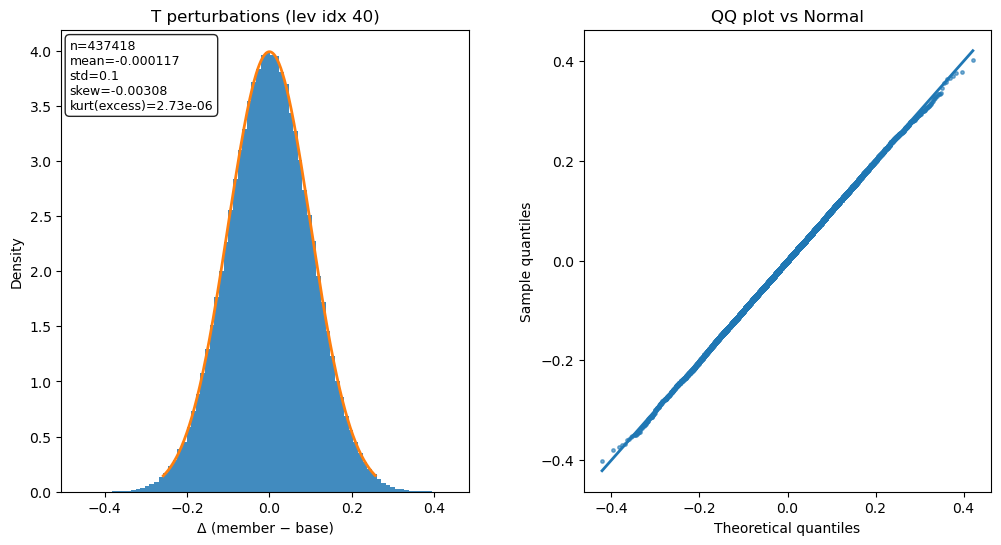


Saved: /global/homes/z/zhan391/analysis/e3sm_s2d/ens_ic_diag_out/1980-05-01-00000/diag_T_hist_qq.png


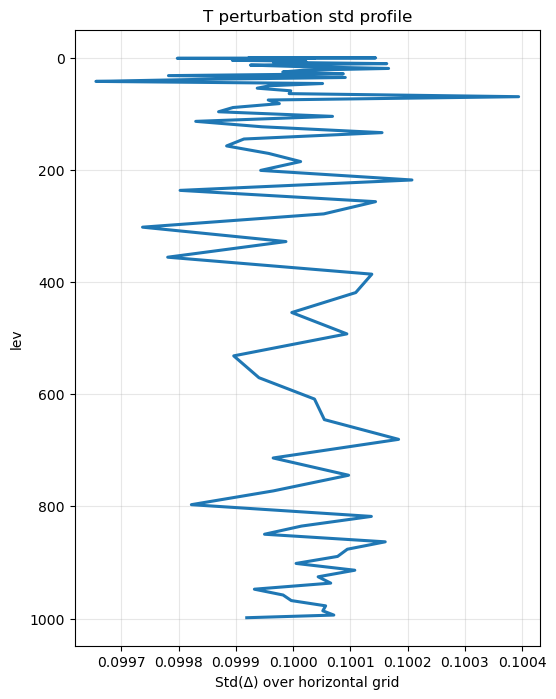

Saved: /global/homes/z/zhan391/analysis/e3sm_s2d/ens_ic_diag_out/1980-05-01-00000/diag_T_std_profile.png


In [29]:
if __name__ == "__main__":

    data_path = "/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT"
    diag_path = "/global/homes/z/zhan391/analysis/e3sm_s2d"
    fig_path = "./"

    init_date = "1980-05-01-00000"
    grid_tag = "_SE.nc"          # or "_360x180.nc"
    
    exp_dict = {
        "Baseline": {"pattern": f"T.base.eam.i.*{grid_tag}", "var": "T"},
        "NONPERT":  {"pattern": f"T.EN00.eam.i.*{grid_tag}", "var": "T"},
        "ENSPERT":  {"pattern": f"T.EN*.eam.i.*{grid_tag}",  "var": "T"},
    }

    # Files live here
    search_dir = f"{data_path}/{init_date}/diag"
    if not os.path.isdir(search_dir):
        raise FileNotFoundError(f"search_dir does not exist: {search_dir}")

    def _pick_one(glob_pattern: str) -> str:
        hits = sorted(glob.glob(glob_pattern))
        if not hits:
            raise FileNotFoundError(f"No files found with: {glob_pattern}")
        hits_date = [p for p in hits if init_date in os.path.basename(p)]
        return hits_date[0] if hits_date else hits[0]

    # --- Resolve files ---
    base_file = _pick_one(os.path.join(search_dir, exp_dict["Baseline"]["pattern"]))

    nonpert_file = None
    nonpert_hits = sorted(glob.glob(os.path.join(search_dir, exp_dict["NONPERT"]["pattern"])))
    if nonpert_hits:
        nonpert_hits_date = [p for p in nonpert_hits if init_date in os.path.basename(p)]
        nonpert_file = nonpert_hits_date[0] if nonpert_hits_date else nonpert_hits[0]

    mem_hits = sorted(glob.glob(os.path.join(search_dir, exp_dict["ENSPERT"]["pattern"])))
    if not mem_hits:
        raise FileNotFoundError("No ensemble member files found for ENSPERT pattern.")

    # Exclude baseline and EN00 from perturbed members
    mem_hits = [p for p in mem_hits if os.path.abspath(p) != os.path.abspath(base_file)]
    mem_hits = [p for p in mem_hits if "EN00" not in os.path.basename(p)]
    print(mem_hits)
    if not mem_hits:
        raise RuntimeError("After excluding baseline/EN00, no perturbed members remain.")

    # --- Configure diagnostics (T only) ---
    out_dir = os.path.join(diag_path, "ens_ic_diag_out", init_date)
    cfg = DiagConfig(
        base_file=base_file,
        member_files=mem_hits,
        out_dir=out_dir,
        variables=("T",),              # <-- only T
        sample_per_member=250_000,
        seed=7,
    )
    diag = EnsembleICDiagnostics(cfg)

    # 1) Baseline vs EN00: only T
    if nonpert_file is not None:
        rep = diag.bfb_check(nonpert_file, variables=("T",))
        print("\n=== Baseline vs EN00 (NONPERT) ===")
        print(f"base_file   : {base_file}")
        print(f"nonpert_file: {nonpert_file}")
        print(f"same_hash   : {rep.same_hash}")
        print(f"  T        max|Δ| = {rep.maxabs_by_var.get('T', np.nan):.6e}")
    else:
        print("\nWARN: NONPERT (EN00) file not found; skipping baseline-vs-EN00 check.")

    # 2) Perturbation stats: pooled T
    stats = diag.perturbation_stats(variables=("T",))
    s = stats.pooled.get("T", {})
    print("\n=== Pooled perturbation stats (ENSPERT) ===")
    print(
        f"T        n={int(s.get('n', 0)):<8d} "
        f"mean={s.get('mean', np.nan): .6e} "
        f"std={s.get('std', np.nan): .6e} "
        f"skew={s.get('skew', np.nan): .3f} "
        f"kurt={s.get('kurt', np.nan): .3f}"
    )

    # 3) Plots (T)
    # Use a robust default lev_index (mid-level) if lev exists
    lev_index = 40  # default for lev=80 (mid)
    try:
        with xr.open_dataset(base_file, decode_times=False, mask_and_scale=False) as _ds:
            if "T" in _ds.variables and "lev" in _ds["T"].dims:
                lev_index = _ds["T"].sizes["lev"] // 2
    except Exception:
        pass

    pngs = []
    png1 = diag.plot_hist_and_qq("T", lev_index=lev_index)
    pngs.append(png1)
    print(f"\nSaved: {png1}")

    try:
        png2 = diag.plot_vertical_std_profile("T")
        pngs.append(png2)
        print(f"Saved: {png2}")
    except Exception as e:
        print(f"WARN: vertical std profile skipped for T: {e}")
        
    # Copy plots to fig_path if requested
    if fig_path and os.path.abspath(fig_path) != os.path.abspath(cfg.out_dir):
        os.makedirs(fig_path, exist_ok=True)
        import shutil

        for p in pngs:
            dst = os.path.join(fig_path, os.path.basename(p))
            if os.path.abspath(dst) != os.path.abspath(p):
                shutil.copy2(p, dst)